# Phase 5: Betting backtest

**Question:** the model is slightly less accurate than the market overall (Phase 4). Could it still make money by betting only where it disagrees with the odds?

The code lives in [`src/backtest.py`](../src/backtest.py); this notebook runs it and explains the results.

## 1. The betting rule

For every match and every outcome (home, draw, away):

```
edge = model probability × bookmaker odds − 1
```

If the edge is above a minimum threshold, bet a flat **£10**.

**Example:** Liverpool vs Bournemouth, draw. The model says 26.6%, the odds are 5.96.
Edge = 0.266 × 5.96 − 1 = **+58%**: the model thinks this bet returns £1.58 per £1 staked on average, so we bet. (Liverpool won; we lost £10.)

Odds are the **average across bookmakers**, a fair middle ground between the best and worst prices available.

In [1]:
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.append("../src")
import backtest as b

results = b.run()
bets, test = results["bets"], results["test"]
print("Model:", results["model_name"])

Model: Logistic regression (C=0.1)


## 2. Choosing the threshold (validation season 2024-25)

The threshold is chosen on the validation season only, never on the test.

In [2]:
print(f"Chosen minimum edge: {results['threshold']:.0%}")
results["validation_table"].round(3)

Chosen minimum edge: 15%


,bets,win_rate,avg_odds,profit,roi
min_edge,,,,,
0.00,373.0,0.351,3.362,-170.2,-0.046
0.05,254.0,0.366,3.436,76.4,0.030
0.10,165.0,0.315,3.704,-5.1,-0.003
0.15,100.0,0.340,3.945,158.2,0.158
0.20,61.0,0.213,4.354,-40.6,-0.067


ROI jumps around from −5% to +16% between neighbouring thresholds. That's a warning sign: with only 60-370 bets, ROI is very noisy, so "the best threshold" may just be luck.

## 3. The test (2025-26 and 2026-27)

In [3]:
results["benchmarks"].round(3)

,bets,win_rate,avg_odds,profit,roi
Always bet home,454.0,0.410,2.634,-579.5,-0.128
Always bet the market favourite,454.0,0.489,1.910,-460.7,-0.101
Our strategy,185.0,0.238,4.403,-322.5,-0.174


Every strategy loses. Even "always bet the favourite" loses about 10%, because of the bookmaker margin (around 5.6% here) plus favourites under-performing. **Our strategy lost 17.4%: worse than the naive benchmarks.**

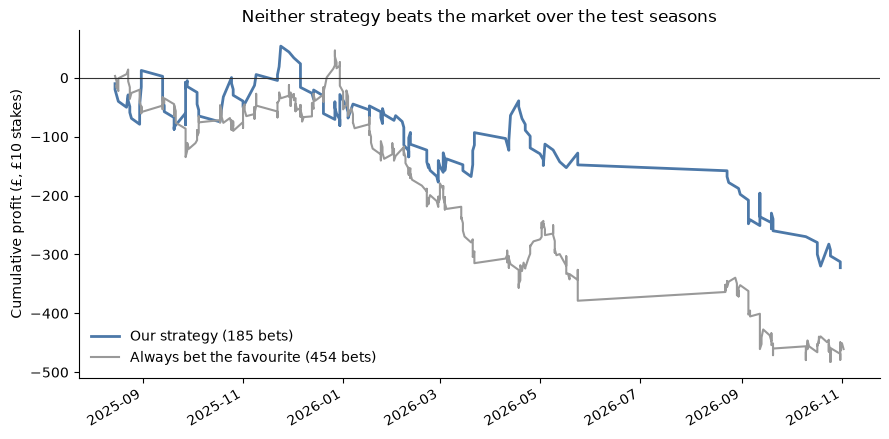

In [4]:
fav = test[["mkt_home_prob", "mkt_draw_prob", "mkt_away_prob"]].to_numpy().argmax(axis=1)
fav_odds = test[["avg_home_odds", "avg_draw_odds", "avg_away_odds"]].to_numpy()[np.arange(len(test)), fav]
fav_won = test["result"].to_numpy() == np.array(["H", "D", "A"])[fav]
favourites = pd.DataFrame({
    "match_date": test["match_date"].to_numpy(),
    "profit": np.where(fav_won, b.STAKE * (fav_odds - 1), -b.STAKE),
}).sort_values("match_date")

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(bets["match_date"], bets["cumulative_profit"], color="#4C78A8", linewidth=2, label="Our strategy (185 bets)")
ax.plot(favourites["match_date"], favourites["profit"].cumsum(), color="#999999", linewidth=1.5, label="Always bet the favourite (454 bets)")
ax.axhline(0, color="#333333", linewidth=0.8)
ax.set_ylabel("Cumulative profit (£, £10 stakes)")
ax.set_title("Neither strategy beats the market over the test seasons")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
fig.autofmt_xdate()
fig.tight_layout()
fig.savefig("../images/cumulative_pnl.png", dpi=150)

## 4. Luck test: is the result skill or chance?

Assume the **market's** probabilities are the truth. Replay the same 185 bets 10,000 times, drawing each result at random from the market's probabilities, and count how often a simulated bettor makes at least as much as we did.

- A small share (under 5%) would mean our result is hard to explain by luck: evidence of real skill.
- A large share means a bettor with **no** edge does as well or better.

81.9% of no-edge simulations made at least as much


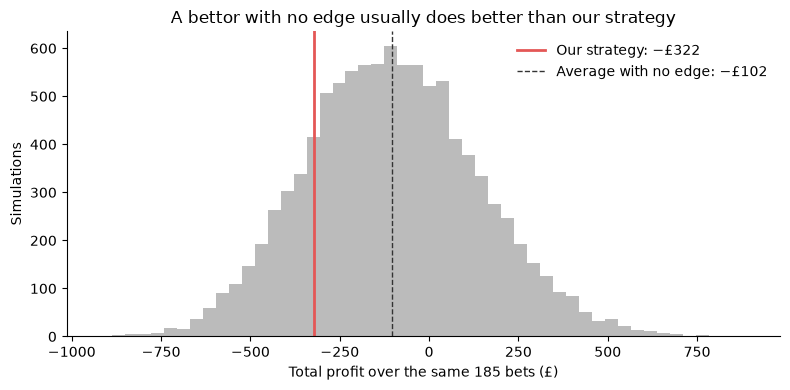

In [5]:
rng = np.random.default_rng(42)
wins = rng.random((b.LUCK_SIMULATIONS, len(bets))) < bets["market_prob"].to_numpy()
simulated = np.where(wins, b.STAKE * (bets["odds"].to_numpy() - 1), -b.STAKE).sum(axis=1)
actual = bets["profit"].sum()

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(simulated, bins=50, color="#BBBBBB")
ax.axvline(actual, color="#E45756", linewidth=2, label=f"Our strategy: −£{abs(actual):,.0f}")
ax.axvline(simulated.mean(), color="#333333", linestyle="--", linewidth=1, label=f"Average with no edge: −£{abs(simulated.mean()):,.0f}")
ax.set_xlabel("Total profit over the same 185 bets (£)")
ax.set_ylabel("Simulations")
ax.set_title("A bettor with no edge usually does better than our strategy")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig("../images/luck_test.png", dpi=150)
print(f"{results['luck_p_value']:.1%} of no-edge simulations made at least as much")

## 5. Why did it lose?

In [6]:
pd.DataFrame({
    "Model's expected ROI": [bets["edge"].mean()],
    "Expected ROI if the market is right": [(bets["market_prob"] * bets["odds"] - 1).mean()],
    "Actual ROI": [results["summary"]["roi"]],
}, index=["185 test bets"]).round(3)

,Model's expected ROI,Expected ROI if the market is right,Actual ROI
185 test bets,0.307,-0.056,-0.174


The model expected **+31%**; the market implied **−5.6%**; reality was **−17%**.

This is **adverse selection**, the most important lesson in the project: the bets with the biggest "edge" are where the model disagrees most with the market, and those are exactly where the model is most likely to be **wrong**. The market knows things the model doesn't (injuries, team news, new signings).

In [7]:
b.breakdown(bets, "bet_on").round(3)

,bets,win_rate,avg_odds,profit,roi
bet_on,,,,,
A,81.0,0.259,4.851,-56.8,-0.070
D,24.0,0.208,5.643,5.3,0.022
H,80.0,0.225,3.577,-271.0,-0.339


**Home bets lost 34%.** That's the calibration problem from Phase 4: the model learned when home teams won 46% of matches, but in the test seasons they won about 41%. It kept finding "value" in home teams that wasn't there.

In [8]:
b.breakdown(bets, "against_big_six").round(3)

,bets,win_rate,avg_odds,profit,roi
against_big_six,,,,,
False,96.0,0.240,3.924,-169.3,-0.176
True,89.0,0.236,4.919,-153.2,-0.172


**Reputation bias is not confirmed.** Bets against Arsenal, Chelsea, Liverpool, Man City, Man United and Tottenham lost just as much as other bets. The Phase 2 hints were most likely one season of noise.

## 6. Robustness: what if we'd picked another threshold?

In [9]:
results["test_table"].round(3)

,bets,win_rate,avg_odds,profit,roi
min_edge,,,,,
0.00,462.0,0.333,3.824,101.4,0.022
0.05,349.0,0.295,4.038,-170.5,-0.049
0.10,252.0,0.266,4.204,-289.7,-0.115
0.15,185.0,0.238,4.403,-322.5,-0.174
0.20,131.0,0.252,4.358,-140.5,-0.107


With a 0% threshold the test shows **+2.2%**. Choosing that after seeing the test results would be **cherry-picking**: the validation season pointed to 15%, and the test results swing just as wildly between thresholds. The honest conclusion is that none of these strategies shows a reliable edge.

## Conclusion

- **The betting market is hard to beat.** A form-and-strength model gets close on accuracy but loses money, and the luck test finds no evidence of skill (82% of no-edge simulations did as well or better).
- **Adverse selection:** the model's biggest disagreements with the market are its biggest mistakes.
- **Home advantage shifted** after the training years, and the model's home bets paid for it (−34% ROI).
- **Reputation bias didn't hold up** out of sample.

**What could give a real edge (future work):**
1. **Information the market prices but the model lacks:** injuries, line-ups, transfers.
2. **Shrinking toward the market:** blend model and market probabilities and only bet small disagreements.
3. **Retraining every week** so the model adapts to changes like falling home advantage.
4. **Better prices:** betting at the best available odds instead of the average cuts the margin.